In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Optional: publication-quality figures
plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.size'] = 12

In [4]:
df = pd.read_csv(r"D:\College\Research\\Astrophysics\ProjectTry\yolo-dagn\gothic_catalog.csv")

print(f"Number of objects: {len(df)}")
df.head()

Number of objects: 29605


,ObjID,SpecObjID,RA,DEC,Redshift,dist_arcsec,dist_kpc,delta_s_kpc,gothic_dist_arcsec,gothic_delta_s_kpc
0,1237650795683512507,299496274514700288,146.95607,-0.342300,0.134680,9.077988,21.678026,25.045581,5.791130,16.530084
1,1237651799621959813,299504520851908608,146.57273,-1.060836,0.060614,9.824729,11.497394,12.199280,6.664669,8.051525
2,1237650795146182725,299516890357721088,146.00779,-0.642272,0.004776,8.773010,0.864970,0.858377,5.434367,0.566529
3,1237650796220121207,299533383032137728,146.34706,0.075416,0.062282,9.420687,11.305631,12.019348,6.192019,7.932770
4,1237650795682791609,299561970334459904,145.36478,-0.342794,0.148621,10.522603,27.299434,32.036252,7.481041,21.143927


In [5]:
# Angular separation (arcsec)
df["gothic_dist_arcsec"] = (
    1.1698 * df["dist_arcsec"] - 4.8283
)

# Prevent negative separations
df["gothic_dist_arcsec"] = np.clip(
    df["gothic_dist_arcsec"],
    a_min=0,
    a_max=None
)

# Physical separation (kpc)
df["gothic_delta_s_kpc"] = (
    0.66 * df["delta_s_kpc"]
)

df.head()

,ObjID,SpecObjID,RA,DEC,Redshift,dist_arcsec,dist_kpc,delta_s_kpc,gothic_dist_arcsec,gothic_delta_s_kpc
0,1237650795683512507,299496274514700288,146.95607,-0.342300,0.134680,9.077988,21.678026,25.045581,5.791130,16.530084
1,1237651799621959813,299504520851908608,146.57273,-1.060836,0.060614,9.824729,11.497394,12.199280,6.664669,8.051525
2,1237650795146182725,299516890357721088,146.00779,-0.642272,0.004776,8.773010,0.864970,0.858377,5.434367,0.566529
3,1237650796220121207,299533383032137728,146.34706,0.075416,0.062282,9.420687,11.305631,12.019348,6.192019,7.932770
4,1237650795682791609,299561970334459904,145.36478,-0.342794,0.148621,10.522603,27.299434,32.036252,7.481041,21.143927


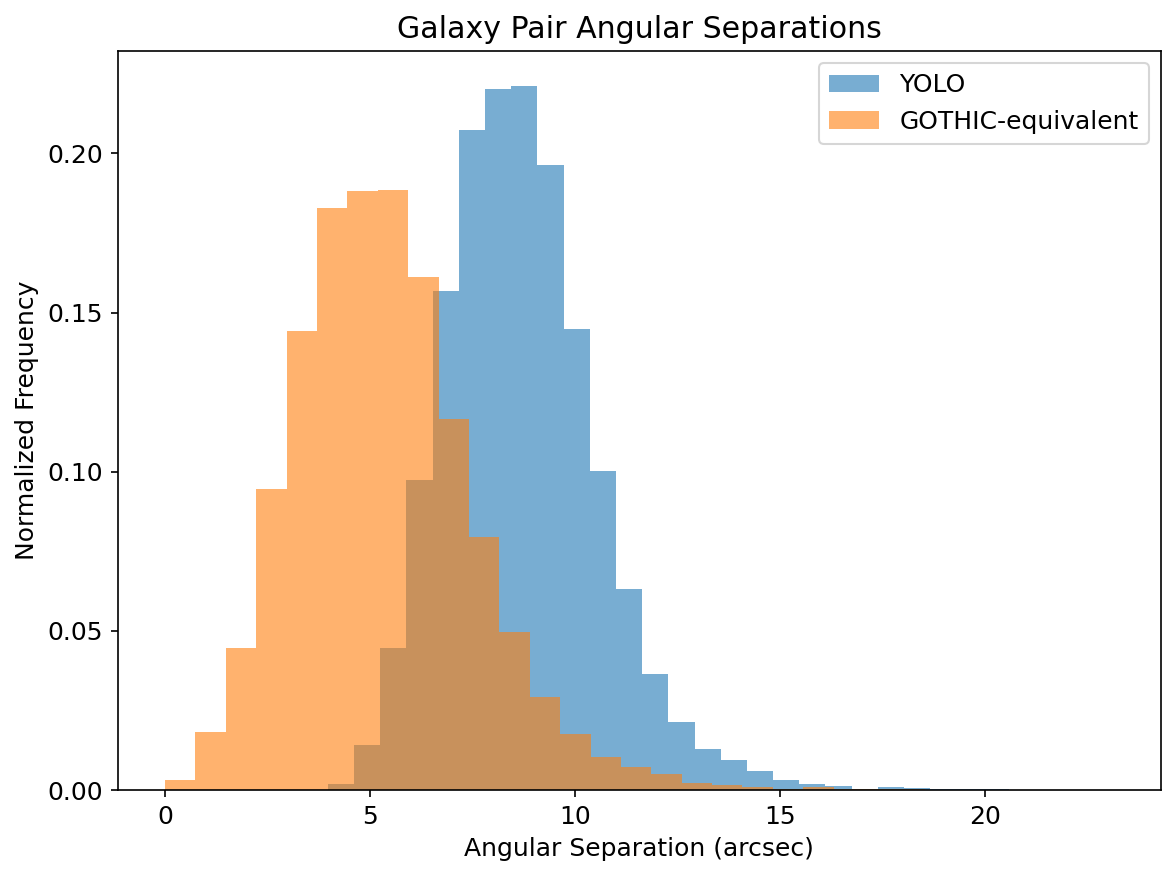

In [6]:
plt.figure(figsize=(8,6))

plt.hist(
    df["dist_arcsec"],
    bins=30,
    alpha=0.6,
    density=True,
    label="YOLO"
)

plt.hist(
    df["gothic_dist_arcsec"],
    bins=30,
    alpha=0.6,
    density=True,
    label="GOTHIC-equivalent"
)

plt.xlabel("Angular Separation (arcsec)")
plt.ylabel("Normalized Frequency")
plt.title("Galaxy Pair Angular Separations")

plt.legend()
plt.tight_layout()
plt.show()

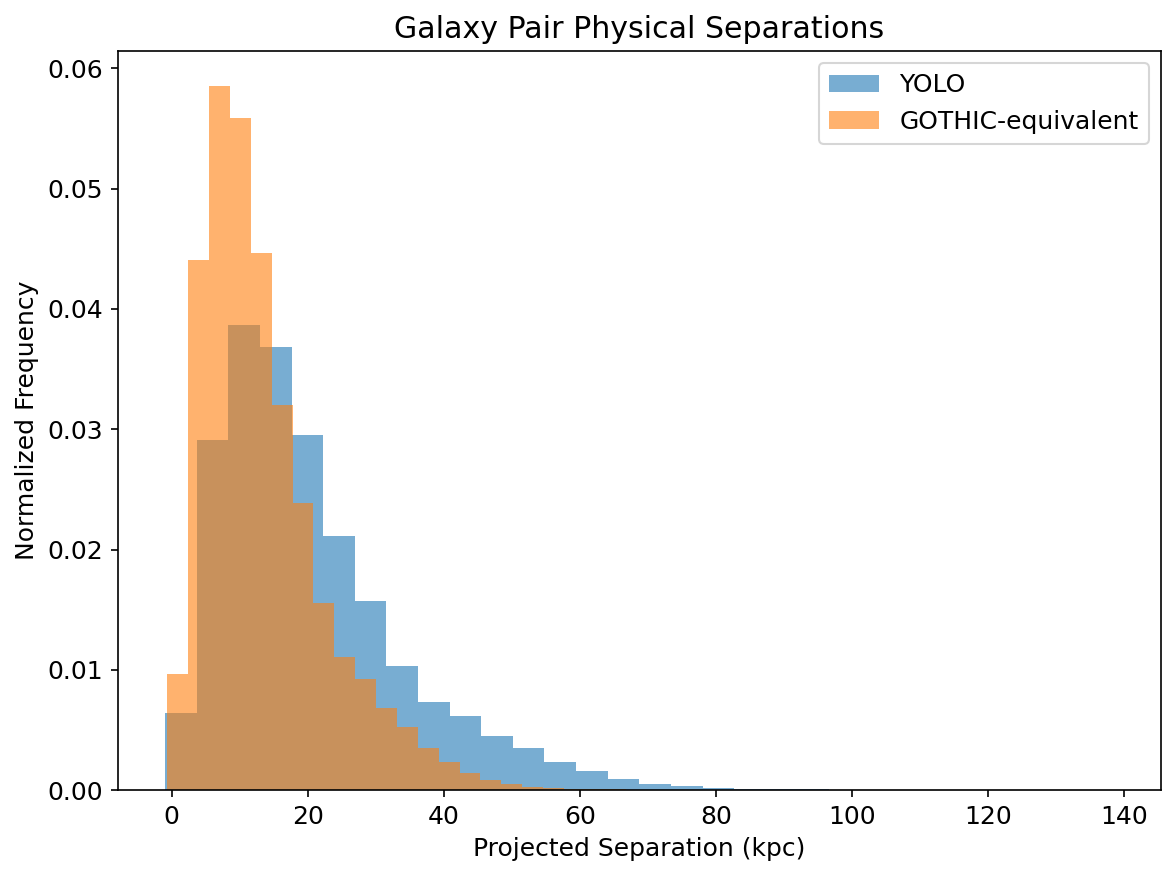

In [7]:
plt.figure(figsize=(8,6))

plt.hist(
    df["delta_s_kpc"],
    bins=30,
    alpha=0.6,
    density=True,
    label="YOLO"
)

plt.hist(
    df["gothic_delta_s_kpc"],
    bins=30,
    alpha=0.6,
    density=True,
    label="GOTHIC-equivalent"
)

plt.xlabel("Projected Separation (kpc)")
plt.ylabel("Normalized Frequency")
plt.title("Galaxy Pair Physical Separations")

plt.legend()
plt.tight_layout()
plt.show()

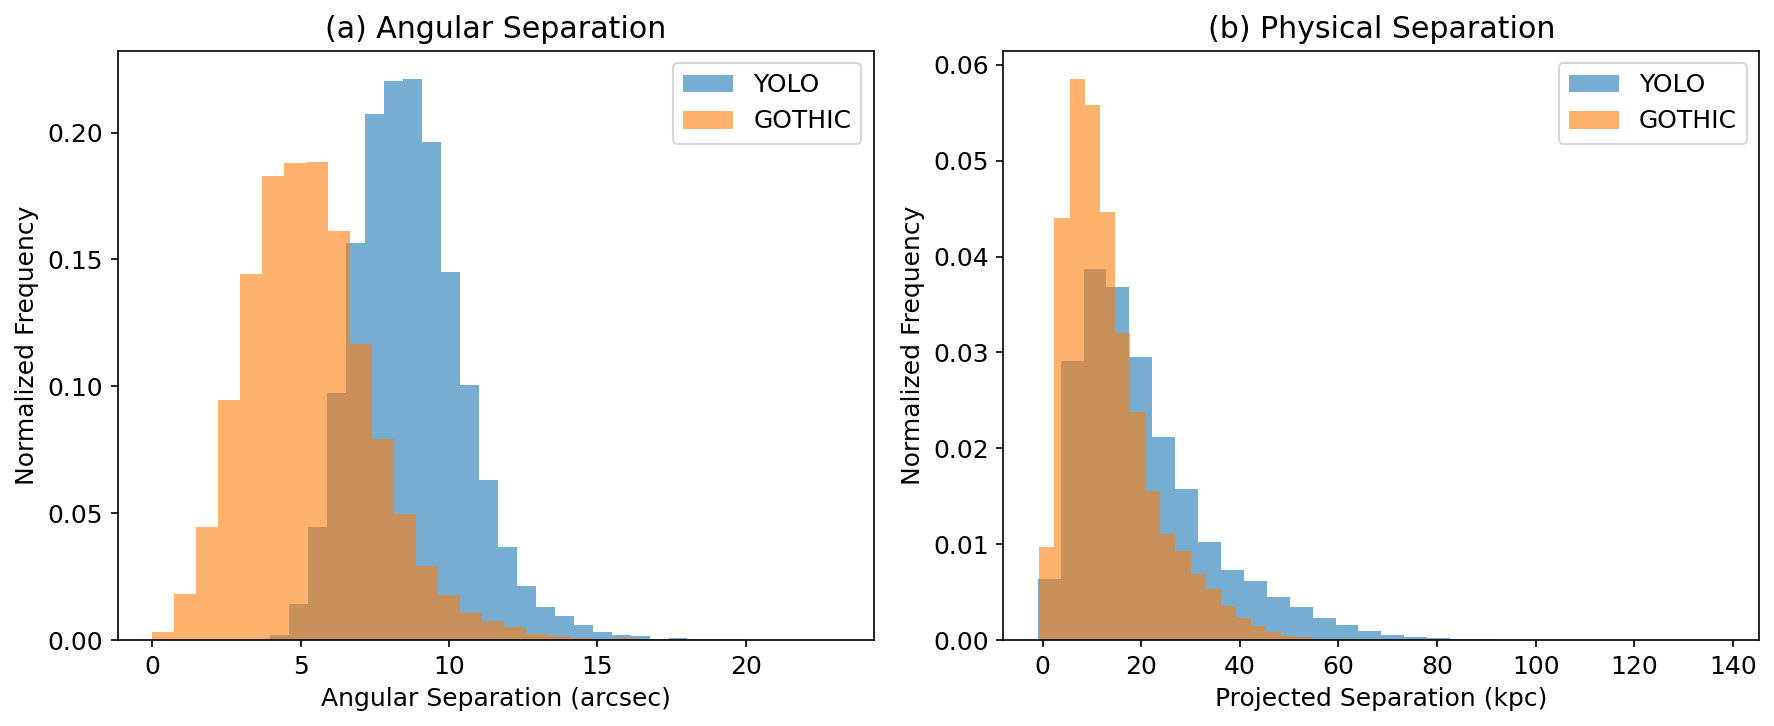

In [8]:
fig, ax = plt.subplots(
    1, 2,
    figsize=(12,5)
)

# Angular
ax[0].hist(
    df["dist_arcsec"],
    bins=30,
    alpha=0.6,
    density=True,
    label="YOLO"
)

ax[0].hist(
    df["gothic_dist_arcsec"],
    bins=30,
    alpha=0.6,
    density=True,
    label="GOTHIC"
)

ax[0].set_xlabel("Angular Separation (arcsec)")
ax[0].set_ylabel("Normalized Frequency")
ax[0].set_title("(a) Angular Separation")
ax[0].legend()

# Physical
ax[1].hist(
    df["delta_s_kpc"],
    bins=30,
    alpha=0.6,
    density=True,
    label="YOLO"
)

ax[1].hist(
    df["gothic_delta_s_kpc"],
    bins=30,
    alpha=0.6,
    density=True,
    label="GOTHIC"
)

ax[1].set_xlabel("Projected Separation (kpc)")
ax[1].set_ylabel("Normalized Frequency")
ax[1].set_title("(b) Physical Separation")
ax[1].legend()

plt.tight_layout()

plt.savefig(
    "YOLO_vs_GOTHIC_histograms.pdf",
    bbox_inches="tight"
)

plt.show()

C:\Users\Bhavesh Mukheja\AppData\Local\Temp\ipykernel_18144\1161377233.py:38: RuntimeWarning: invalid value encountered in log10
  np.log10(df["delta_s_kpc"].min()),
C:\Users\Bhavesh Mukheja\AppData\Local\Temp\ipykernel_18144\1161377233.py:50: RuntimeWarning: invalid value encountered in log10
  np.log10(df["gothic_delta_s_kpc"].min()),


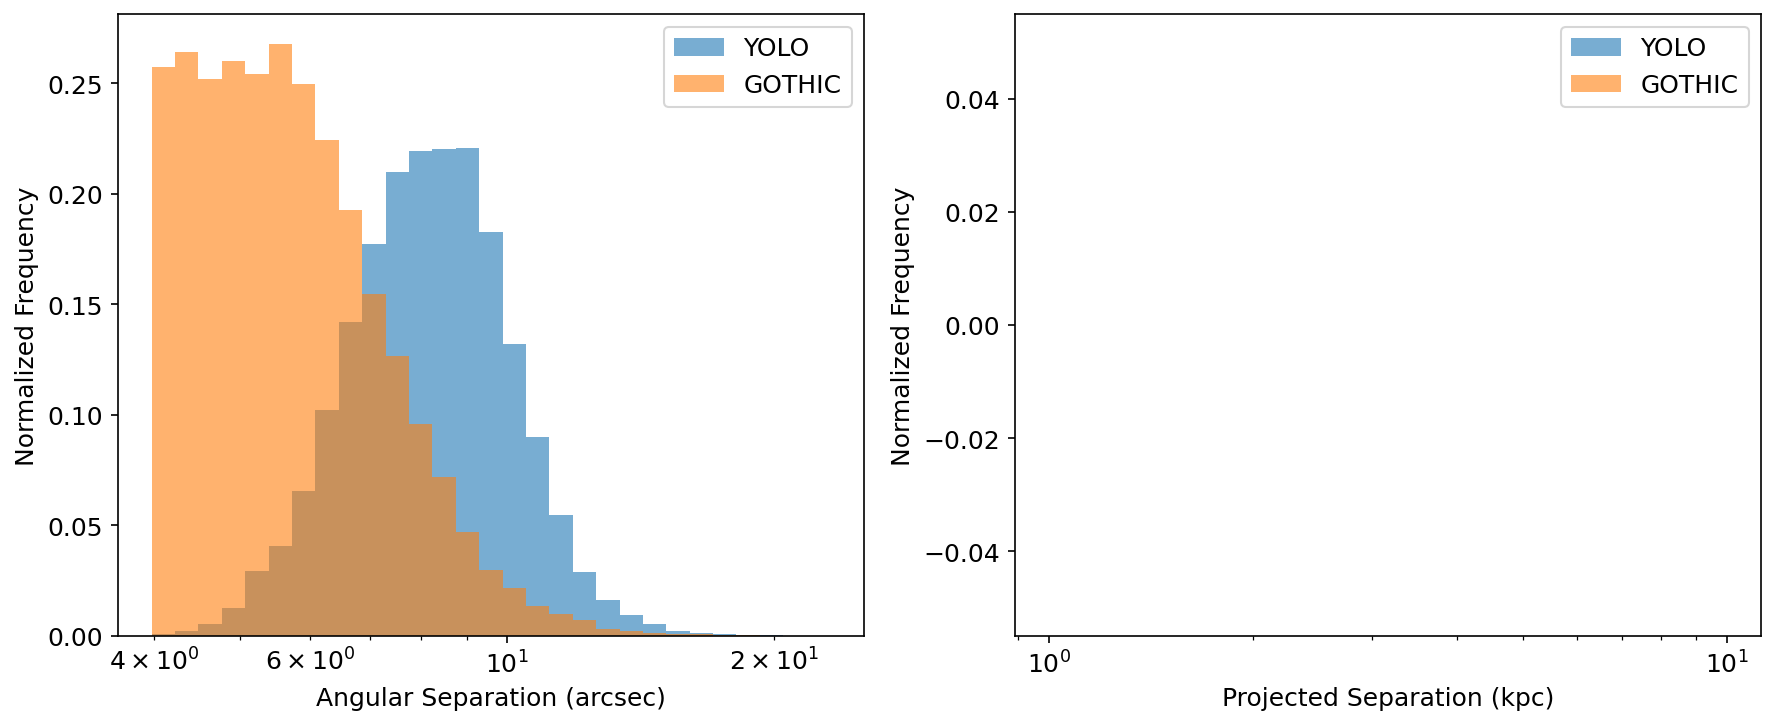

In [9]:
fig, ax = plt.subplots(
    1, 2,
    figsize=(12,5)
)

ax[0].hist(
    df["dist_arcsec"],
    bins=np.logspace(
        np.log10(df["dist_arcsec"].min()),
        np.log10(df["dist_arcsec"].max()),
        30
    ),
    alpha=0.6,
    density=True,
    label="YOLO"
)

ax[0].hist(
    df["gothic_dist_arcsec"][df["gothic_dist_arcsec"] > 0],
    bins=np.logspace(
        np.log10(df["dist_arcsec"].min()),
        np.log10(df["dist_arcsec"].max()),
        30
    ),
    alpha=0.6,
    density=True,
    label="GOTHIC"
)

ax[0].set_xscale("log")
ax[0].set_xlabel("Angular Separation (arcsec)")
ax[0].set_ylabel("Normalized Frequency")
ax[0].legend()

ax[1].hist(
    df["delta_s_kpc"],
    bins=np.logspace(
        np.log10(df["delta_s_kpc"].min()),
        np.log10(df["delta_s_kpc"].max()),
        30
    ),
    alpha=0.6,
    density=True,
    label="YOLO"
)

ax[1].hist(
    df["gothic_delta_s_kpc"],
    bins=np.logspace(
        np.log10(df["gothic_delta_s_kpc"].min()),
        np.log10(df["gothic_delta_s_kpc"].max()),
        30
    ),
    alpha=0.6,
    density=True,
    label="GOTHIC"
)

ax[1].set_xscale("log")
ax[1].set_xlabel("Projected Separation (kpc)")
ax[1].set_ylabel("Normalized Frequency")
ax[1].legend()

plt.tight_layout()
plt.show()